<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/5g_ddpm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo probabilístico de difusión (DDPM)
En esta libreta programaremos un modelo probabilístico de difusión para eliminación de ruido (DDPM, Ho et al., 2020) y lo aplicaremos al conjunto de imágenes de rostros CelebA.

In [ ]:
import os
import math

from collections.abc import Callable

import matplotlib.pyplot as plt
import numpy as np

import torch as th
from torch import nn
import torch.nn.functional as F
from torch.optim import Adam

from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter

from datasets import load_dataset
import torchvision.transforms.v2 as T

N_EPOCAS = 20
T_LOTE = 64
T_IMAGEN = 64
N_PASOS = 400
N_BLOQUES = 3
MULT_CANALES = (1, 2, 4, 8)
SEED = 42
N_MUESTRAS_IMG = 32
N_TRAB = os.cpu_count() or 1
LR = 0.0002
TBDIR = './runs/'
DC = th.device('cuda:0' if th.cuda.is_available() else 'cpu')

np.random.seed(SEED)
th.manual_seed(SEED)

## Conjunto de imágenes
Cargamos el conjunto de imágenes de rostros CelebA desde Hugging Face Hub.

In [ ]:
ds = load_dataset("flwrlabs/celeba", split="train")

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/19 [00:00<?, ?it/s]

Definimos las transformaciones que redimensionan y recortan al centro las imágenes, las convierten a `Tensor` y escalan sus valores a un rango de $-1$ a $1$. Las transformaciones se aplican al vuelo con `set_transform` cada vez que se accede a un elemento del conjunto.

In [ ]:
tr = T.Compose([T.ToImage(),
                T.Resize(T_IMAGEN, antialias=True),
                T.CenterCrop(T_IMAGEN),
                T.ToDtype(th.float32, scale=True),
                T.Normalize(mean=(0.5, 0.5, 0.5),
                            std=(0.5, 0.5, 0.5))])

def transforma(lote):
  return {'image': [tr(img.convert('RGB')) for img in lote['image']]}

ds.set_transform(transforma)

dl = DataLoader(ds,
                batch_size=T_LOTE,
                shuffle=True,
                drop_last=True,
                num_workers=N_TRAB,
                pin_memory=True,
                persistent_workers=True,
                prefetch_factor=2)

lote = next(iter(dl))
print(f'Imágenes = {lote["image"].shape}')

Imágenes = torch.Size([64, 3, 64, 64])


Definimos funciones para visualizar imágenes:

In [ ]:
def muestra_imagenes(imgs: np.ndarray) -> None:
  t_muestra = imgs.shape[0]
  n_filas = math.floor(math.sqrt(t_muestra))
  n_cols = math.ceil(t_muestra / n_filas)

  fig, ax = plt.subplots(nrows=n_filas, ncols=n_cols, squeeze=False)

  for i in range(n_filas):
    for j in range(n_cols):
      idx = i * n_cols + j
      ax[i, j].axis('off')
      if idx < t_muestra:
        ax[i, j].imshow(imgs[idx])

  fig.subplots_adjust(wspace=-0.5, hspace=0)
  plt.show()

Mostramos un lote del conjunto de datos.

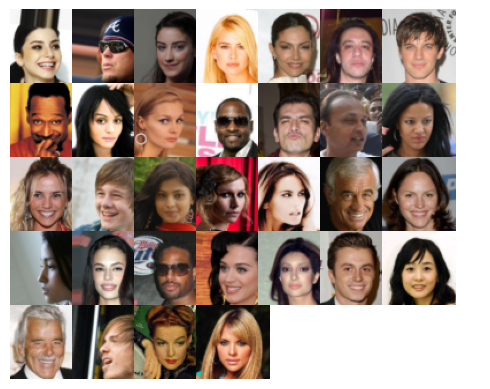

In [ ]:
def rescala(X: th.Tensor,
            std: float = 0.5,
            mean: float = 0.5) -> np.ndarray:

  return (X * std + mean).clamp(0, 1).movedim(-3, -1).detach().cpu().numpy()


muestra_imagenes(rescala(lote["image"][:N_MUESTRAS_IMG]))

## Proceso de difusión hacia adelante
El proceso hacia adelante agrega ruido gaussiano en $T$ pasos de acuerdo con los valores $\beta^{[1]}, \ldots, \beta^{[T]}$:

$$
q(\mathbf{x}^{[t]} \mid \mathbf{x}^{[t-1]}) = \mathcal{N}\left(\mathbf{x}^{[t]} \mid \sqrt{1 - \beta^{[t]}}\,\mathbf{x}^{[t-1]}, \beta^{[t]} \mathbf{I}\right)
$$

Dado $\alpha^{[t]} = 1 - \beta^{[t]}$ y $\bar{\alpha}^{[t]} = \prod_{s=1}^{t} \alpha^{[s]}$, podemos obtener $\mathbf{x}^{[t]}$ directamente a partir de $\mathbf{x}^{[0]}$ como sigue:

$$
\mathbf{x}^{[t]} = \sqrt{\bar{\alpha}^{[t]}}\,\mathbf{x}^{[0]} + \sqrt{1 - \bar{\alpha}^{[t]}}\,\boldsymbol{\epsilon}, \quad \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})
$$

En esta libreta usaremos la programación coseno de Nichol y Dhariwal (2021), que define directamente $\bar{\alpha}^{[t]}$:

$$
\bar{\alpha}^{[t]} = \frac{f(t)}{f(0)}, \quad f(t) = \cos^2\left(\frac{t / T + s}{1 + s} \cdot \frac{\pi}{2}\right)
$$

donde $s = 0.008$ es un desplazamiento pequeño que evita que $\beta^{[t]}$ sea demasiado pequeño cerca de $t = 0$. A partir de $\bar{\alpha}^{[t]}$ obtenemos los valores

$$
\beta^{[t]} = 1 - \frac{\bar{\alpha}^{[t]}}{\bar{\alpha}^{[t-1]}},
$$

que se recortan a un máximo de $0.999$ para evitar que $\beta^{[t]}$ llegue a $1$ cuando $t$ se acerca a $T$. Los índices de los pasos van de $0$ a $T - 1$ en el código.

In [ ]:
def prog_coseno(t: float,
                s: float = 0.008) -> float:
  return math.cos(((t + s) / (1.0 + s)) * 0.5 * math.pi)**2

def betas_coseno(n_pasos: int,
                 s: float = 0.008,
                 max_beta: float = 0.999) -> th.Tensor:
  betas = []
  for t in range(n_pasos):
    t1 = t / n_pasos
    t2 = (t + 1) / n_pasos

    # alfa^[t] = alfa_barra^[t] / alfa_barra^[t-1]
    alfa_t = prog_coseno(t2, s) / prog_coseno(t1, s)

    betas.append(min(1 - alfa_t, max_beta))

  return th.tensor(betas)

Visualizamos los valores de $\beta$ de acuerdo a la programación coseno para un número dado de paso, comparándolos con la programación lineal.

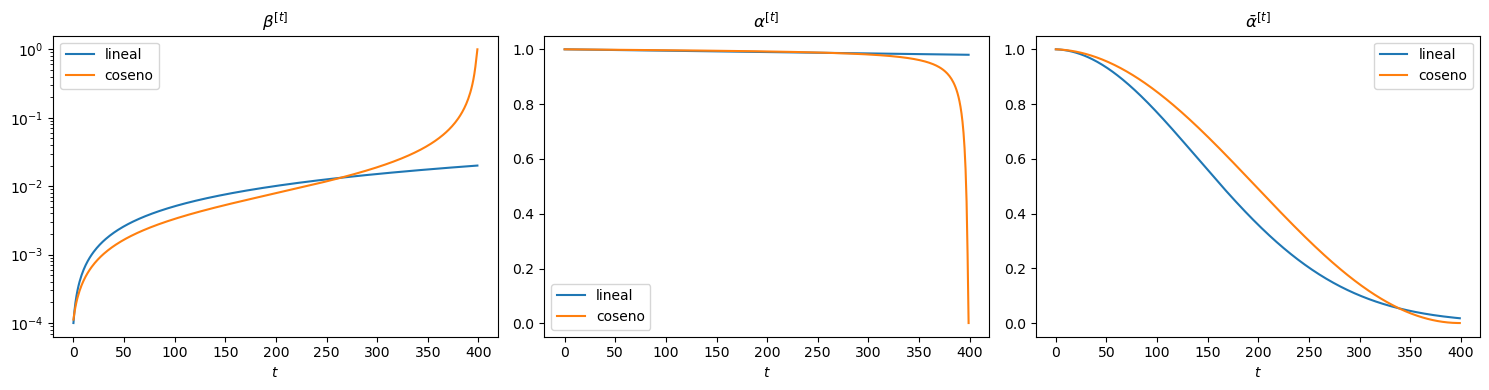

In [ ]:
betas_cos = betas_coseno(N_PASOS)
betas_lin = th.linspace(1e-4, 0.02, N_PASOS)

fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (15, 4))
for betas, nombre in [(betas_lin, 'lineal'), (betas_cos, 'coseno')]:
  alfas = 1.0 - betas
  axs[0].plot(betas, label = nombre)
  axs[1].plot(alfas, label = nombre)
  axs[2].plot(th.cumprod(alfas, dim = 0), label = nombre)

axs[0].set_yscale('log')
axs[0].set_title(r'$\beta^{[t]}$')
axs[1].set_title(r'$\alpha^{[t]}$')
axs[2].set_title(r'$\bar{\alpha}^{[t]}$')
for ax in axs:
  ax.set_xlabel('$t$')
  ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
class AgregaRuido(nn.Module):
  def __init__(self,
               n_pasos: int = 1000) -> None:
    super().__init__()

    self.n_pasos = n_pasos

    betas = betas_coseno(n_pasos)
    alphas = 1.0 - betas
    self.register_buffer('betas', betas)
    self.register_buffer('alphas', alphas)
    self.register_buffer('alphas_barra', th.cumprod(alphas, dim = 0))

  def forward(self,
              x0: th.Tensor,
              t: th.Tensor,
              ruido: th.Tensor) -> th.Tensor:

    ab = self.alphas_barra[t][:, None, None, None]

    return th.sqrt(ab) * x0 + th.sqrt(1.0 - ab) * ruido

Visualizamos cómo se va eliminando el ruido en una de las muestras, desde $\mathbf{x}^{[T]}$ hasta $\mathbf{x}^{[0]}$.

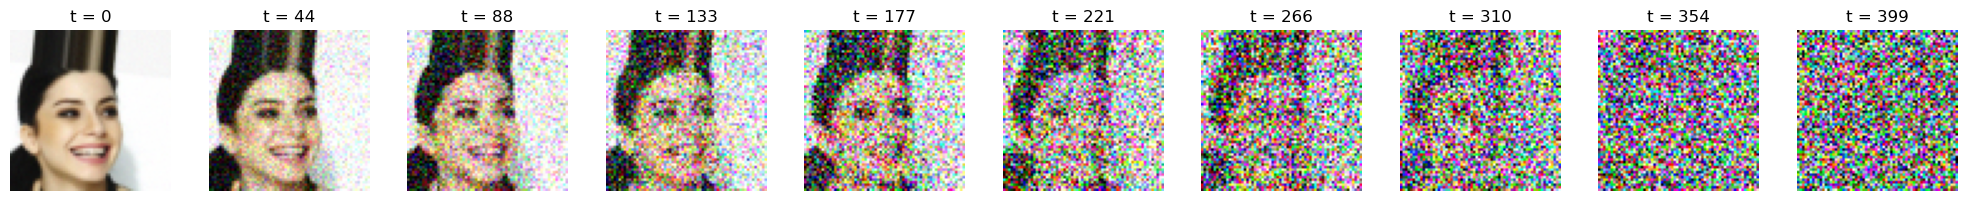

In [ ]:
agrega_ruido = AgregaRuido(N_PASOS)

pasos = th.linspace(0, N_PASOS - 1, 10).long()
x0 = lote["image"][:1].expand(len(pasos), -1, -1, -1)
xt = agrega_ruido(x0, pasos, th.randn_like(x0))

fig, axs = plt.subplots(1, len(pasos), figsize = (20, 2))
for i, t in enumerate(pasos):
  axs[i].imshow(rescala(xt[i]))
  axs[i].set_title(f't = {t.item()}')
  axs[i].axis('off')
plt.tight_layout()
plt.show()

## Red para predecir ruido
La red $\boldsymbol{\epsilon}_\theta(\mathbf{x}^{[t]}, t)$ recibe la imagen con ruido y el paso $t$ y predice el ruido $\boldsymbol{\epsilon}$. Usamos una U-Net con bloques residuales condicionados en $t$.

### Codificación del paso de tiempo
Para representar el paso $t$ usamos la codificación posicional sinusoidal de Vaswani et al., ahora con el paso en lugar de la posición en la secuencia:

\begin{align*}
\operatorname{PE}(t,2i) & = \sin\left[\frac{t}{10000^{\left(\frac{2i}{d_{modelo}}\right)}}\right]\\
\operatorname{PE}(t,2i+1) & = \cos\left[\frac{t}{10000^{\left(\frac{2i}{d_{modelo}}\right)}}\right]
\end{align*}

donde $d_{modelo}$ es el tamaño del _embedding_ e $i \in \{0, \ldots, d_{modelo}/2 - 1\}$ el índice de un par de dimensiones. Como los pasos son discretos, precalculamos la tabla para los $T$ pasos y la indexamos con $t$. Esta codificación fija pasa después por una MLP aprendida dentro de la U-Net.

In [ ]:
class CodificacionTiempo(nn.Module):
  def __init__(self,
               n_pasos: int,
               d_modelo: int) -> None:
    super().__init__()

    # Creamos tensor con los índices de las dimensiones pares 2i = 0, 2, 4, ...
    # dos_i: [d_modelo // 2, 1]
    dos_i = th.arange(0, d_modelo, 2, dtype = th.float).reshape(-1, 1)

    # Creamos tensor de pasos 0, 1, ..., T - 1
    # pasos: [n_pasos, 1]
    pasos = th.arange(0, n_pasos, dtype = th.float).reshape(-1, 1)

    # Frecuencias de cada par de dimensiones
    # omega: [d_modelo // 2, 1]
    omega = 1.0 / 10000**(dos_i / d_modelo)

    # Ángulos para cada paso y par de dimensiones
    # angulos: [n_pasos, d_modelo // 2]
    angulos = pasos @ omega.T

    cod_t = th.zeros((n_pasos, d_modelo))
    cod_t[:, 0::2] = th.sin(angulos) # Para pares
    cod_t[:, 1::2] = th.cos(angulos) # Para impares

    # Registramos tensor de codificación
    self.register_buffer('cod_t', cod_t)

  def forward(self,
              t: th.Tensor) -> th.Tensor:
    # t: [lote] -> [lote, d_modelo]
    return self.cod_t[t]

### Bloque residual
Cada bloque aplica dos veces normalización por grupos, activación SiLU y una convolución de $3 \times 3$. El _embedding_ del paso se proyecta al número de canales de salida y se suma después de la primera convolución. Si cambia el número de canales, el atajo usa una convolución de $1 \times 1$.

In [ ]:
class BloqueResNet(nn.Module):
  def __init__(self,
               c_ent: int,
               c_sal: int,
               t_canales: int,
               grupos: int = 32,
               p_dropout: float = 0.1,
               eps: float = 1e-6) -> None:
    super().__init__()

    self.norm1 = nn.GroupNorm(grupos, c_ent, eps = eps, affine = True)
    self.conv1 = nn.Conv2d(c_ent, c_sal, kernel_size = 3, stride = 1, padding = 1)

    self.proy_emb_t = nn.Linear(t_canales, c_sal)

    self.norm2 = nn.GroupNorm(grupos, c_sal, eps = eps, affine = True)
    self.dropout = nn.Dropout(p_dropout)
    self.conv2 = nn.Conv2d(c_sal, c_sal, kernel_size = 3, stride = 1, padding = 1)

    if c_ent != c_sal:
      self.atajo = nn.Conv2d(c_ent, c_sal, kernel_size = 1, stride = 1, padding = 0)
    else:
      self.atajo = nn.Identity()

  def forward(self,
              x: th.Tensor,
              t_emb: th.Tensor) -> th.Tensor:
    y = self.conv1(F.silu(self.norm1(x)))
    y = y + self.proy_emb_t(F.silu(t_emb))[:, :, None, None]
    y = self.conv2(self.dropout(F.silu(self.norm2(y))))

    return self.atajo(x) + y

### Submuestreo y sobremuestreo
El submuestreo es una convolución de $3 \times 3$ con paso 2. El sobremuestreo es una interpolación por vecino más cercano seguida de una convolución de $3 \times 3$.

In [ ]:
class Downsample(nn.Module):
  def __init__(self,
               c_ent: int) -> None:
    super().__init__()
    self.conv = nn.Conv2d(c_ent,
                          c_ent,
                          kernel_size = 3,
                          stride = 2,
                          padding = 1)

  def forward(self,
              x: th.Tensor) -> th.Tensor:
    return self.conv(x)

class Upsample(nn.Module):
  def __init__(self,
               c_ent: int) -> None:
    super().__init__()

    self.up = nn.Sequential(nn.Upsample(scale_factor = 2,
                                        mode = 'nearest'),
                            nn.Conv2d(c_ent,
                                      c_ent,
                                      kernel_size = 3,
                                      padding = 1))

  def forward(self,
              x: th.Tensor) -> th.Tensor:
    return self.up(x)

### Codificador
Cada nivel tiene `n_bloques` bloques residuales seguidos de un submuestreo, excepto el último nivel, que no tiene submuestreo. Se guardan la entrada y la salida de cada capa para las conexiones de salto, así como su número de canales.

In [ ]:
class Codificador(nn.Module):
  def __init__(self,
               ini_canales: int = 32,
               mult_canales: tuple[int, ...] = (1, 2, 4, 8),
               t_canales: int = 128,
               n_bloques: int = 3,
               grupos: int = 32,
               atn_res: tuple[int, ...] = (16,),
               p_dropout: float = 0.1) -> None:
    super().__init__()

    self.bloques = nn.ModuleList()
    self.canales = [ini_canales]
    c_ent = ini_canales
    for i, m in enumerate(mult_canales):
      for _ in range(n_bloques):
        self.bloques.append(BloqueResNet(c_ent,
                                         ini_canales * m,
                                         t_canales,
                                         grupos,
                                         p_dropout))
        c_ent = ini_canales * m
        self.canales.append(c_ent)

      if i != len(mult_canales) - 1:
        self.bloques.append(Downsample(c_ent))
        self.canales.append(c_ent)

  def forward(self,
              x: th.Tensor,
              t_emb: th.Tensor) -> tuple[th.Tensor, list[th.Tensor]]:
    salidas = [x]
    for b in self.bloques:
      x = b(x, t_emb) if isinstance(b, BloqueResNet) else b(x)
      salidas.append(x)

    return x, salidas

### Decodificador
Cada nivel tiene `n_bloques + 1` bloques residuales seguidos de un sobremuestreo, excepto el último nivel, que no tiene sobremuestreo. Cada bloque residual concatena a su entrada una de las salidas guardadas del codificador en orden inverso.

In [ ]:
class Decodificador(nn.Module):
  def __init__(self,
               c_ent: int,
               canales: list[int],
               ini_canales: int = 32,
               mult_canales: tuple[int, ...] = (1, 2, 4, 8),
               t_canales: int = 128,
               n_bloques: int = 3,
               grupos: int = 32,
               p_dropout: float = 0.1) -> None:
    super().__init__()

    canales = list(canales)
    self.bloques = nn.ModuleList()
    for i, m in reversed(list(enumerate(mult_canales))):
      for _ in range(n_bloques + 1):
        self.bloques.append(BloqueResNet(c_ent + canales.pop(),
                                         ini_canales * m,
                                         t_canales,
                                         grupos,
                                         p_dropout))
        c_ent = ini_canales * m

      if i != 0:
        self.bloques.append(Upsample(c_ent))

  def forward(self,
              x: th.Tensor,
              t_emb: th.Tensor,
              salidas: list[th.Tensor]) -> th.Tensor:
    for b in self.bloques:
      if isinstance(b, BloqueResNet):
        x = b(th.cat([x, salidas.pop()], dim = 1), t_emb)
      else:
        x = b(x)

    return x

### U-Net
La U-Net calcula el _embedding_ del paso (codificación sinusoidal seguida de una MLP) una sola vez y lo pasa a todos los bloques residuales. Entre el codificador y el decodificador hay dos bloques residuales que conservan la resolución.

In [ ]:
class UNet(nn.Module):
  def __init__(self,
               c_img: int = 3,
               ini_canales: int = 32,
               mult_canales: tuple[int, ...] = (1, 2, 4, 8),
               n_bloques: int = 3,
               grupos: int = 32,
               p_dropout: float = 0.1,
               n_pasos: int = 1000) -> None:
    super().__init__()

    self.n_pasos = n_pasos

    t_canales = 4 * ini_canales

    self.cod_t = CodificacionTiempo(n_pasos, ini_canales)
    self.densa_t = nn.Sequential(nn.Linear(ini_canales, t_canales),
                                 nn.SiLU(),
                                 nn.Linear(t_canales, t_canales))

    self.conv_ent = nn.Conv2d(c_img, ini_canales, kernel_size = 3, padding = 1)

    self.codificador = Codificador(ini_canales,
                                   mult_canales,
                                   t_canales,
                                   n_bloques,
                                   grupos,
                                   p_dropout)

    c = self.codificador.canales[-1]
    self.medio = nn.ModuleList([BloqueResNet(c, c, t_canales, grupos, p_dropout),
                                BloqueResNet(c, c, t_canales, grupos, p_dropout)])

    self.decodificador = Decodificador(c,
                                       self.codificador.canales,
                                       ini_canales,
                                       mult_canales,
                                       t_canales,
                                       n_bloques,
                                       grupos,
                                       p_dropout)

    self.norm_sal = nn.GroupNorm(grupos, ini_canales, eps = 1e-6)
    self.conv_sal = nn.Conv2d(ini_canales, c_img, kernel_size = 3, padding = 1)

  def forward(self,
              x: th.Tensor,
              t: th.Tensor) -> th.Tensor:
    t_emb = self.densa_t(self.cod_t(t))

    h = self.conv_ent(x)
    h, salidas = self.codificador(h, t_emb)

    for b in self.medio:
      h = b(h, t_emb)

    h = self.decodificador(h, t_emb, salidas)

    return self.conv_sal(F.silu(self.norm_sal(h)))

Instanciamos y probamos nuestra U-Net:

In [ ]:
unet = UNet(c_img = 3,
            ini_canales = 32,
            mult_canales = MULT_CANALES,
            n_bloques = N_BLOQUES,
            grupos = 32,
            p_dropout = 0.1,
            n_pasos = N_PASOS)
t = th.randint(0, N_PASOS, (lote["image"].shape[0],))
print(unet(lote["image"], t).shape)
print(f'Parámetros: {sum(p.numel() for p in unet.parameters()) / 1e6:.1f} M')

torch.Size([64, 3, 64, 64])
Parámetros: 18.1 M


## DDPM
Ho et al. entrenan la red con una versión simplificada de la cota variacional, que se reduce a predecir el ruido agregado:

$$
\mathcal{L}_{\text{simple}} = \mathbb{E}_{t, \mathbf{x}^{[0]}, \boldsymbol{\epsilon}}\left[\left\| \boldsymbol{\epsilon} - \boldsymbol{\epsilon}_\theta\left(\sqrt{\bar{\alpha}^{[t]}}\,\mathbf{x}^{[0]} + \sqrt{1 - \bar{\alpha}^{[t]}}\,\boldsymbol{\epsilon}, t\right) \right\|^2\right]
$$

donde $t$ se muestrea uniformemente.

Para generar, se parte de $\mathbf{x}^{[T]} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ y se aplica el proceso inverso paso a paso. En cada paso, primero estimamos $\mathbf{x}^{[0]}$ a partir del ruido predicho y recortamos la estimación al intervalo $[-1, 1]$ de los datos:

$$
\hat{\mathbf{x}}^{[0]} = \operatorname{recorta}_{[-1, 1]}\left(\frac{\mathbf{x}^{[t]} - \sqrt{1 - \bar{\alpha}^{[t]}}\,\boldsymbol{\epsilon}_\theta(\mathbf{x}^{[t]}, t)}{\sqrt{\bar{\alpha}^{[t]}}}\right)
$$

Después calculamos la media de la distribución posterior $q(\mathbf{x}^{[t-1]} \mid \mathbf{x}^{[t]}, \hat{\mathbf{x}}^{[0]})$ y muestreamos $\mathbf{x}^{[t-1]}$:

$$
\tilde{\boldsymbol{\mu}}^{[t]} = \frac{\sqrt{\bar{\alpha}^{[t-1]}}\,\beta^{[t]}}{1 - \bar{\alpha}^{[t]}}\,\hat{\mathbf{x}}^{[0]} + \frac{\sqrt{\alpha^{[t]}}\,(1 - \bar{\alpha}^{[t-1]})}{1 - \bar{\alpha}^{[t]}}\,\mathbf{x}^{[t]}
$$

$$
\mathbf{x}^{[t-1]} = \tilde{\boldsymbol{\mu}}^{[t]} + \sigma^{[t]}\mathbf{z}, \quad \mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})
$$

con $(\sigma^{[t]})^2 = \beta^{[t]}$, $\bar{\alpha}^{[0]} = 1$ y $\mathbf{z} = \mathbf{0}$ en el último paso.

Sin el recorte, esta media es igual a la que usan Ho et al.:

$$
\tilde{\boldsymbol{\mu}}^{[t]} = \frac{1}{\sqrt{\alpha^{[t]}}}\left(\mathbf{x}^{[t]} - \frac{\beta^{[t]}}{\sqrt{1 - \bar{\alpha}^{[t]}}}\,\boldsymbol{\epsilon}_\theta(\mathbf{x}^{[t]}, t)\right)
$$

El recorte evita que los errores de la red se amplifiquen en los primeros pasos del muestreo. Ahí la programación coseno tiene valores de $\beta^{[t]}$ cercanos a $1$ y el factor $1/\sqrt{\alpha^{[t]}}$ es muy grande.

In [ ]:
class DDPM(nn.Module):
  def __init__(self,
               modelo: nn.Module) -> None:
    super().__init__()

    self.modelo = modelo
    self.agrega_ruido = AgregaRuido(self.modelo.n_pasos)

  def forward(self,
              X: th.Tensor,
              t: th.Tensor) -> th.Tensor:
    return self.modelo(X, t)

  def difusion(self,
               x0: th.Tensor) -> tuple[th.Tensor, th.Tensor, th.Tensor]:
    t = th.randint(0, self.modelo.n_pasos, (x0.shape[0],), device = x0.device)
    ruido = th.randn_like(x0)
    return self.agrega_ruido(x0, t, ruido), t, ruido

  @th.inference_mode()
  def muestrear(self,
                n: int,
                forma: tuple[int, ...],
                n_guardar: int = 10) -> tuple[th.Tensor, list[th.Tensor]]:
    x = th.randn(n, *forma, device = self.agrega_ruido.alphas.device)
    guardar = set(th.linspace(0, self.modelo.n_pasos - 1, n_guardar).long().tolist())
    trayectoria = []

    for t in reversed(range(self.modelo.n_pasos)):
      tt = th.full((n,), t, device = x.device, dtype = th.long)
      ruido_pred = self.modelo(x, tt)

      ab_t = self.agrega_ruido.alphas_barra[t]
      ab_ant = self.agrega_ruido.alphas_barra[t - 1] if t > 0 else th.ones_like(ab_t)

      # estimación de x0 recortada al intervalo de los datos
      x0_pred = (x - th.sqrt(1.0 - ab_t) * ruido_pred) / th.sqrt(ab_t)
      x0_pred = x0_pred.clamp(-1.0, 1.0)

      # media de la posterior q(x^[t-1] | x^[t], x0)
      coef_x0 = th.sqrt(ab_ant) * self.agrega_ruido.betas[t] / (1.0 - ab_t)
      coef_xt = th.sqrt(self.agrega_ruido.alphas[t]) * (1.0 - ab_ant) / (1.0 - ab_t)
      media = coef_x0 * x0_pred + coef_xt * x

      if t > 0:
        x = media + th.sqrt(self.agrega_ruido.betas[t]) * th.randn_like(x)
      else:
        x = media

      if t in guardar:
        trayectoria.append(x.clamp(-1.0, 1.0).cpu())

    return x.clamp(-1.0, 1.0), trayectoria

## Funciones para el entrenamiento
Para facilitar el entrenamiento, definimos diversas funciones.

### Registrar información para TensorBoard
Para guardar información que pueda visualizarse con TensorBoard, instanciamos la clase `SummaryWriter` del submódulo `tensorboard` del módulo `utils` y escribimos información mediante los distintos métodos disponibles (por ejemplo, `add_scalar`, `add_image`, `add_histogram`, etc.).

In [ ]:
def registra_info_tboard(writer: SummaryWriter,
                         epoca: int,
                         hist: dict[str, np.ndarray]) -> None:
  for (m, v) in hist.items():
    writer.add_scalar(m, v[epoca], epoca)

### Paso de entrenamiento
Definimos una función que realiza un paso de entrenamiento, a la cual llamaremos `paso_ent`. Esta función recibe como argumentos:
* El modelo como una instancia de `DDPM` (`modelo`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* Una instancia de `Tensor` con el lote de imágenes (`X`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

La función calcula la pérdida simplificada para el lote, obtiene los gradientes, los recorta a norma 1 y actualiza todos los parámetros del modelo mediante el optimizador pasado como argumento.

In [ ]:
def paso_ent(modelo: nn.Module,
             fp: Callable,
             opt: th.optim.Optimizer,
             X: th.Tensor,
             disp: str | th.device = 'cpu') -> float:
  # Ponemos los gradientes asociados a los parámetros
  # a actualizar en cero
  opt.zero_grad()

  tipo_disp = th.device(disp).type

  # Se habilita precisión mixta solo si el dispositivo es cuda y
  # soporta bfloat16 de forma nativa (capacidad de cómputo >= 8.0)
  usa_amp = (tipo_disp == 'cuda' and th.cuda.get_device_capability(disp)[0] >= 8)

  with th.autocast(device_type = tipo_disp,
                   dtype = th.bfloat16, enabled = usa_amp):

    # Paso hacia adelante
    xt, t, ruido = modelo.difusion(X)
    y_hat = modelo(xt, t)

    # Se calcula la pérdida
    perdida = fp(y_hat, ruido)

  # Se obtienen los gradientes
  perdida.backward()

  # Se recortan los gradientes
  nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)

  # Se actualizan todos los parámetros del modelo
  opt.step()

  return perdida.item()

### Época de entrenamiento
Definimos una función para realizar una época de entrenamiento, que llamaremos `entrena_epoca`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* El cargador de datos del subconjunto de entrenamiento (`dl`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

In [ ]:
def entrena_epoca(modelo: nn.Module,
                  fp: Callable,
                  opt: th.optim.Optimizer,
                  dl: th.utils.data.DataLoader,
                  disp: str | th.device = 'cpu') -> float:
  n_total = 0
  suma_perdida = 0.0

  modelo.train()
  for i, lote in enumerate(dl):
    X = lote["image"].to(disp)

    perdida_paso = paso_ent(modelo,
                            fp,
                            opt,
                            X,
                            disp)

    n_lote = X.shape[0]
    n_total += n_lote

    # La pérdida es el promedio sobre las imágenes del lote
    suma_perdida += perdida_paso * n_lote

  perdida_epoca = suma_perdida / n_total

  return perdida_epoca

### Ciclo principal
También definimos el ciclo de entrenamiento principal, que llamaremos `entrena`. Esta función recibe como argumentos:

* El modelo como una instancia de `DDPM` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* El cargador de datos del subconjunto de entrenamiento (`dl`).
* El número de épocas de entrenamiento (`n_epocas`).
* El dispositivo en el que se ejecutará el modelo (`disp`).
* La ruta al directorio donde se guardará la información para TensorBoard (`tbdir`).

In [ ]:
def entrena(modelo: nn.Module,
            fp: Callable,
            opt: th.optim.Optimizer,
            dl: th.utils.data.DataLoader,
            n_epocas = 20,
            disp: str | th.device = 'cpu',
            tbdir = 'runs/') -> tuple[nn.Module, dict[str, np.ndarray]]:

  hist = {
    'perdida': np.zeros(n_epocas)
    }

  tbwriter = SummaryWriter(tbdir)

  modelo.to(disp)
  for e in range(n_epocas):
    hist['perdida'][e] = entrena_epoca(modelo,
                                       fp,
                                       opt,
                                       dl,
                                       disp)

    registra_info_tboard(tbwriter, e, hist)


    print(f'Época {e}: '
          f'Pérdida = {hist["perdida"][e]:.3f}')

  tbwriter.close()

  return modelo, hist

## Entrenamiento
Instanciamos el modelo, el optimizador, la función de pérdida y lo entrenamos.

In [ ]:
ddpm = DDPM(UNet(n_pasos = N_PASOS)).to(DC)

opt = Adam(ddpm.parameters(),
           lr = LR)

perdida = nn.MSELoss(reduction = 'mean')

ddpm, perdidas = entrena(ddpm,
                         perdida,
                         opt,
                         dl,
                         n_epocas = N_EPOCAS,
                         disp = DC,
                         tbdir = TBDIR)

Época 0: Pérdida = 0.067
Época 1: Pérdida = 0.040
Época 2: Pérdida = 0.037
Época 3: Pérdida = 0.036
Época 4: Pérdida = 0.036
Época 5: Pérdida = 0.035
Época 6: Pérdida = 0.035
Época 7: Pérdida = 0.035
Época 8: Pérdida = 0.035
Época 9: Pérdida = 0.034
Época 10: Pérdida = 0.034
Época 11: Pérdida = 0.034
Época 12: Pérdida = 0.034
Época 13: Pérdida = 0.034
Época 14: Pérdida = 0.034
Época 15: Pérdida = 0.034
Época 17: Pérdida = 0.034
Época 18: Pérdida = 0.033
Época 19: Pérdida = 0.034


Graficamos las pérdidas.

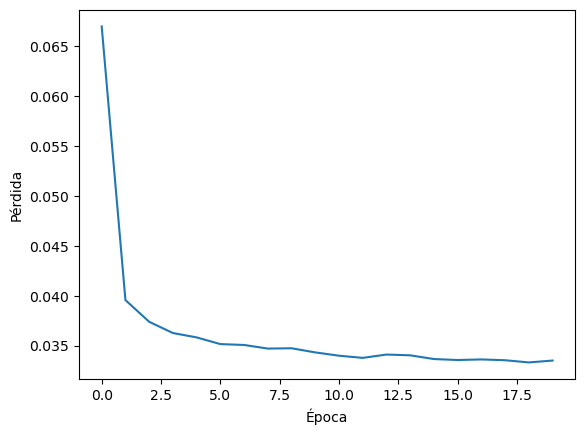

In [ ]:
plt.plot(perdidas["perdida"])
plt.xlabel(u'Época')
plt.ylabel(u'Pérdida')
plt.show()

## Generación de muestras
Partimos de ruido gaussiano y aplicamos los $T$ pasos del proceso inverso.

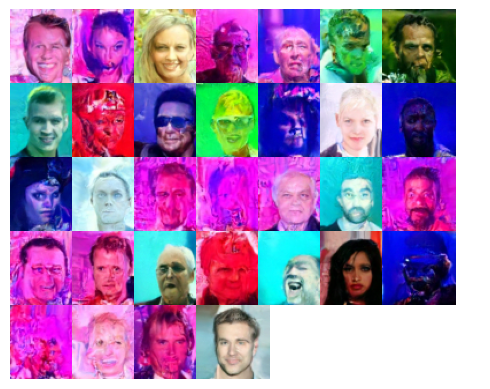

In [ ]:
ddpm.eval()
muestras, trayectoria = ddpm.muestrear(N_MUESTRAS_IMG, (3, T_IMAGEN, T_IMAGEN))

muestra_imagenes(rescala(muestras))

Visualizamos cómo se va eliminando el ruido en una de las muestras, desde $\mathbf{x}_T$ hasta $\mathbf{x}_0$:

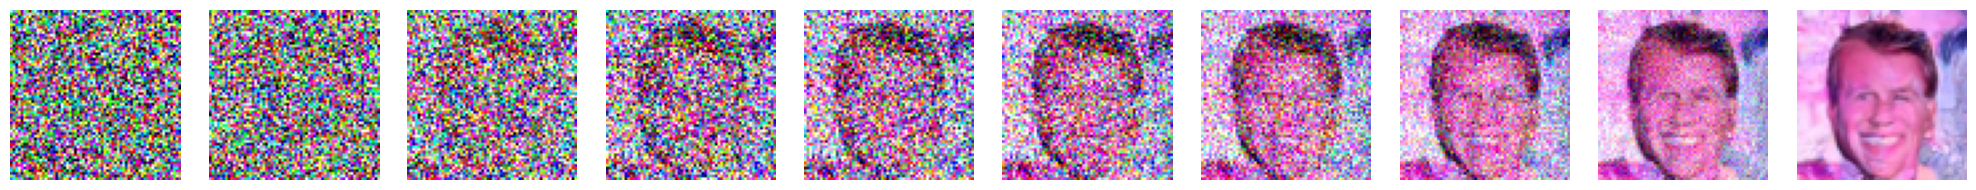

In [ ]:
fig, axs = plt.subplots(1, len(trayectoria), figsize = (20, 2))
for i, xt in enumerate(trayectoria):
  axs[i].imshow(rescala(xt[0]))
  axs[i].axis('off')
plt.tight_layout()
plt.show()